In [1]:
%matplotlib inline
from cotree import *
from cotree import dtmae_flex as flex
from importlib.resources import files
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


if torch.cuda.is_available():
    # Get the current GPU device
    current_device = torch.cuda.current_device()
    print("Current GPU Device:", torch.cuda.get_device_name(current_device))
else:
    print("CUDA is not available. No GPU detected.")

Using device: cpu
CUDA is not available. No GPU detected.


# Data preprocessing

`OmicsDataset(data_folder, labels)` loads the named group folders from `data_folder`. Each group has four omics subfolders; CSV rows are species and columns are time points. 

In [3]:
# Load example data
# For other data, run 
    # data_folder = './data' (path)
    # file_name = ['Multi_Replication'] (replace by sub folder name)
    # dataset = OmicsDataset(data_folder, file_name) 

data_dir = files("cotree") / "data" 

dataset = OmicsDataset(data_dir, ["Multi_Replication"])

`flex.training_dataset(samples, modality_names, config)` fits preprocessing and creates consecutive-time pairs. The names `['G', 'R', 'P', 'M']` match the loader's tensor order.

| Setting | Effect |
|---|---|
| `G: scale_factor=0.5` | Divide by the fitted mean × 0.5. |
| `M: filter_zero_var=True` | Remove invariant metabolite features. |
| `P: keep_indices` | Retain the listed protein columns. |

Mean scaling is enabled by default. Each cell contributes `T−1` pairs.

In [4]:
# Remove cytoplasmic forms of membrane proteins by retaining the other indices.
keep_protein_index = [i for i, p in enumerate(dataset.names["proteomics"])
                      if not p.startswith("C_")]

# Flexible preprocessing reproduces the original four-omics scaling and filtering.
training_data = flex.training_dataset(dataset.samples, ['G', 'R', 'P', 'M'], {
    'G': {'scale_factor': 0.5},
    'M': {'filter_zero_var': True},
    'P': {'keep_indices': keep_protein_index},
})
total_samples = len(training_data)

In [5]:
# Remove species names for invariant metabolites and protein
dataset.names["metabolomics"] = dataset.names["metabolomics"][training_data.feature_indices['M'].cpu().numpy()]
dataset.names["proteomics"] = dataset.names["proteomics"][training_data.feature_indices['P'].cpu().numpy()]
dataset.names["genomics"] = dataset.names["genomics"][training_data.feature_indices['G'].cpu().numpy()]
dataset.names["transcriptomics"] = dataset.names["transcriptomics"][training_data.feature_indices['R'].cpu().numpy()]


# name of species
species = list(dataset.names['genomics'])+list(dataset.names['metabolomics'])+list(dataset.names['proteomics'])


# print species number
for key,val in dataset.names.items():
    print(f"Species in {key}: {len(val)}")

Species in genomics: 493
Species in transcriptomics: 455
Species in proteomics: 458
Species in metabolomics: 181


# Representation Learning

`flex.autoencoder` builds the model from these settings:

| Input | Meaning |
|---|---|
| `raw_dims=input_size` | Feature counts **after preprocessing**. |
| `encoded_modalities`, `latent_dims` | Encode G/M/P into 10/30/50 features. |
| `passthrough_modalities` | No encoder for RNA, directly pass to the predictor. |
| `hidden_encoder`, `hidden_decoder`, `hidden_predictor` | Layer widths; `[100]` means one 100-unit layer. |
| `predictor_inputs` | Inputs for each prediction. |
| `normalize_input` | Encoder input LayerNorm for M/P. |

In [ ]:
# Autoencoder parameters for G, M, P, and R.
input_size = {m: x.numel() for m, x in training_data[0][0].items()}
hidden_layer_encoder = {'M': [100], 'P': [250], 'R': [250], 'G': [100]}
latent_dim = {'M': 30, 'P': 50, 'G': 10}
hidden_layer_decoder = {'M': [100], 'P': [250], 'G': [100]}
hidden_layer_predictor = {'M': [100], 'P': [250], 'G': [100]}

encoded_modalities = ['G', 'M', 'P']
passthrough_modalities = ['R']
predictor_inputs = {'G': ['G', 'M', 'P'], 'M': ['M', 'P'], 'P': ['R', 'M', 'P']}
normalize_input = ['M', 'P']  

**Optional hyperparameter tuning**

To tune, replace the next training cell with this example.

`n_trials` sets the number of candidates; `n_epochs_per_trial` sets their training budget. `search_space` supplies candidate widths/dimensions; `lr`, `batch_size`, and `dropout` stay fixed. `study_name` and `storage` identify and save the study. The search also tunes loss weights and the reconstruction/prediction balance.

```python
best = flex.tune_dtmae(
    training_data, input_size,
    encoded_modalities=encoded_modalities,
    passthrough_modalities=passthrough_modalities,
    predictor_inputs=predictor_inputs,
    normalize_input=normalize_input,
    n_trials=20,
    n_epochs_per_trial=50,
    val_fraction=0.2,
    seed=42,
    device=device,
    search_space={
        'hidden_choices': [100, 250],
        'latent_G': [8, 10, 16],
        'latent_M': [16, 30, 32],
        'latent_P': [32, 50, 64],
        'lr': 5e-3,
        'batch_size': 200,
        'dropout': 0.0,
    },
    study_name='Multi_Replication',
    storage='sqlite:///cotree_tuning.db',
)

# Inspect the selected settings and all Pareto candidates.
print({key: value for key, value in best.items() if not key.startswith('_')})
print([(trial.number, trial.values) for trial in best['_pareto_trials']])

# Build and train a fresh final model using ALL selected settings.
latent_dim = best['latent_dims']
torch.manual_seed(42)
RL_model = flex.autoencoder(
    raw_dims=input_size,
    encoded_modalities=encoded_modalities,
    passthrough_modalities=passthrough_modalities,
    latent_dims=latent_dim,
    hidden_encoder=best['hidden_encoder'],
    hidden_decoder=best['hidden_decoder'],
    hidden_predictor=best['hidden_predictor'],
    predictor_inputs=predictor_inputs,
    normalize_input=normalize_input,
    dropout_rate=best['dropout_rate'],
)
RL_model, training_history = flex.train_dtmae(
    RL_model, training_data,
    n_epochs=200,
    lr=best['lr'],
    batch_size=best['batch_size'],
    gamma=best['gamma'],
    eta_curr=best['eta_curr'],
    lambda_manifold=best['lambda_manifold'],
    val_fraction=0.2,
    seed=42,
    device=device,
)
```

Continue with embedding extraction and the remaining sections. Their feature
and module dimensions are computed from the selected model settings.

`flex.train_dtmae(RL_model, training_data, ...)` returns the model and loss history.

| Input | Meaning |
|---|---|
| `n_epochs`, `batch_size` | Training passes and pairs per batch. |
| `lr`, `weight_decay` | Adam learning rate and weight decay. |
| `gamma`, `eta_curr` | Modality weights and reconstruction/prediction balance; `0.5` balances both equally. |
| `val_fraction` | Hold out whole cells. |
| `step_size`, `scheduler_gamma` | Halve learning rate every 200 epochs. |

`seed` controls randomness; initialization is seeded separately. `device` selects CPU or CUDA throughout the analysis.

In [7]:
torch.manual_seed(42)  # Seed model initialization as well as the training split.
RL_model = flex.autoencoder(
    raw_dims=input_size,
    encoded_modalities=encoded_modalities,
    passthrough_modalities=passthrough_modalities,
    latent_dims=latent_dim,
    hidden_encoder=hidden_layer_encoder,
    hidden_decoder=hidden_layer_decoder,
    hidden_predictor=hidden_layer_predictor,
    predictor_inputs=predictor_inputs,
    normalize_input=normalize_input,
    dropout_rate=0,
)
RL_model, training_history = flex.train_dtmae(
    RL_model, training_data,
    n_epochs=200,
    batch_size=200,
    lr=5e-3,
    weight_decay=0,
    gamma={'G': 2.0, 'M': 1.0, 'P': 2.0},  # Weights for both reconstruction and prediction.
    eta_curr=0.5,
    val_fraction=0.01,
    step_size=200,
    scheduler_gamma=0.5,
    seed=42,
    device=device,
)

Epoch    1/200  train=17.2644  val=15.5719  | pred (tr/val) G:2.9874/2.7090  M:9.8938/9.2168  P:0.7810/0.5713


Epoch   20/200  train=2.2187  val=2.4670  | pred (tr/val) G:0.0808/0.0649  M:1.7822/2.0532  P:0.0233/0.0672


Epoch   40/200  train=0.9735  val=1.1619  | pred (tr/val) G:0.0553/0.0449  M:0.4991/0.6501  P:0.0116/0.0674


Epoch   60/200  train=0.3247  val=0.4835  | pred (tr/val) G:0.0295/0.0370  M:0.1937/0.2755  P:0.0068/0.0674


Epoch   80/200  train=0.1704  val=0.3325  | pred (tr/val) G:0.0237/0.0356  M:0.0959/0.1438  P:0.0047/0.0672


...

Epoch  120/200  train=0.0933  val=0.2699  | pred (tr/val) G:0.0192/0.0311  M:0.0404/0.1076  P:0.0030/0.0668


Epoch  140/200  train=0.0757  val=0.2587  | pred (tr/val) G:0.0179/0.0327  M:0.0275/0.0971  P:0.0025/0.0635


Epoch  160/200  train=0.3492  val=0.3835  | pred (tr/val) G:0.0267/0.0314  M:0.0233/0.1119  P:0.0023/0.0649


Epoch  180/200  train=0.0644  val=0.2569  | pred (tr/val) G:0.0169/0.0325  M:0.0197/0.1008  P:0.0020/0.0646


Epoch  200/200  train=0.0569  val=0.2541  | pred (tr/val) G:0.0162/0.0325  M:0.0158/0.1041  P:0.0017/0.0629


In [8]:
# Get embeddings and processed species data using the fitted preprocessing.
latent_embedding = flex.extract_latent_embeddings(
    RL_model, dataset.samples, training_data, device=device)
processed_data = training_data.transform_samples(dataset.samples)
M_stack = processed_data['M'].numpy()
P_stack = processed_data['P'].numpy()
G_stack = processed_data['G'].numpy()

print(f"Number of latent features: {latent_embedding.shape[1]}")

Number of latent features: 90


In [9]:
# Concatenated data of gene, metabolite and protein

data_raw = np.concatenate((G_stack,M_stack,P_stack),axis = -1)

# Functional module detection

In [10]:
# Estimate functional module
# Higher cosine value indicates a more accurate estimation
# Increasing epoch number for better results
latent_size = latent_dim['G']+latent_dim['P']+latent_dim['M']
f_vector = np.zeros((latent_size,input_size['G']+input_size['M']+input_size['P']))
for index in range(latent_size):
    f_vector[index] = function_module_estimation(RL_model, training_data, index, lambda_reg=0.001, input_size = input_size, device = device, learning_rate=0.01, 
                 epochs=10)

Index 0,Mean Cosine: 0.808594, Reg: 0.040555


Index 1,Mean Cosine: 0.742466, Reg: 0.044479


Index 2,Mean Cosine: 0.015802, Reg: 0.009780


Index 3,Mean Cosine: 0.849396, Reg: 0.036118


Index 4,Mean Cosine: 0.600689, Reg: 0.045172


...

Index 85,Mean Cosine: 0.868535, Reg: 0.031205


Index 86,Mean Cosine: 0.621107, Reg: 0.049811


Index 87,Mean Cosine: 0.710940, Reg: 0.057062


Index 88,Mean Cosine: 0.700510, Reg: 0.031492


Index 89,Mean Cosine: 0.756660, Reg: 0.039556


In [11]:
# Find species. The new function returns the threshold, indices, and diagnostics.
functional_module = {}
G_tensor = torch.as_tensor(G_stack, dtype=torch.float32)
M_tensor = torch.as_tensor(M_stack, dtype=torch.float32)
P_tensor = torch.as_tensor(P_stack, dtype=torch.float32)

for i in range(f_vector.shape[0]):
    selected_tau, selected_index, cosine_diff, taus = functional_module_species(
        G_tensor, M_tensor, P_tensor, f_vector[i], RL_model, i, input_size, device)
    functional_module[f'Functional Module {i+1}'] = np.array(species)[selected_index]

Functional Module: 1 Finished.


Functional Module: 2 Finished.


Functional Module: 3 Finished.


Functional Module: 4 Finished.


Functional Module: 5 Finished.


...

Functional Module: 86 Finished.


Functional Module: 87 Finished.


Functional Module: 88 Finished.


Functional Module: 89 Finished.


Functional Module: 90 Finished.


In [12]:
# Example of functional module

functional_module['Functional Module 16']

array(['M_udpg_c', 'M_udpgal_c', 'M_ap_c', 'M_glyc_c', 'M_glyc3p_c',
       'M_pap_c', 'M_pg3p_c', 'M_clpn_c', 'M_12dgr_c', 'M_udpgalfur_c',
       'M_fa_c', 'M_pc_c', 'M_cmp_c', 'M_ctp_c', 'M_dcyt_c', 'M_dcmp_c',
       'M_dcdp_c', 'M_gsn_c', 'M_gua_c', 'M_gmp_c', 'M_gdp_c', 'M_dgsn_c',
       'M_dgdp_c', 'M_ura_c', 'M_ump_c', 'M_udp_c', 'M_utp_c', 'M_duri_c',
       'M_dutp_c', 'M_adn_c', 'M_ade_c', 'M_dad_2_c', 'M_damp_c',
       'M_datp_c', 'M_thymd_c', 'M_dtdp_c', 'M_dttp_c', 'M_glu__L_c',
       'M_gln__L_c', 'M_ppi_c', 'M_g1p_c', 'M_f6p_c', 'M_pi_c', 'M_amp_c',
       'M_adp_c', 'M_atp_c', 'M_10fthfglu3_c', 'M_nh3_c', 'M_pep_c',
       'M_pyr_c', 'M_xu5p__D_c', 'M_ru5p__D_c', 'M_prpp_c', 'M_e4p_c',
       'M_fdp_c', 'M_g3p_c', 'M_2dr1p_c', 'M_nadh_c', 'M_nadp_c',
       'M_nadph_c', 'M_3pg_c', 'M_2pg_c', 'M_lac__L_c', 'M_actp_c',
       'M_ac_c', 'M_acald_c', 'M_nac_c', 'M_ribflv_c', 'M_fad_c',
       'M_thmpp_c', 'M_5fthf_c', 'M_methfglu3_c', 'M_mlthfglu3_c',
       'M_sprm_c',

In [13]:
latent_size = sum(latent_dim[m] for m in encoded_modalities)
importance_score = np.zeros((latent_size, sum(input_size[m] for m in 'GMP')))
for index in range(latent_size):
    importance_score[index] = function_score_estimation(
        RL_model, index, dataset, training_data=training_data, device=device)
    print(f'Latent dim {index+1} finished.')

Latent dim 1 finished.
Latent dim 2 finished.


Latent dim 3 finished.


Latent dim 4 finished.
Latent dim 5 finished.


Latent dim 6 finished.


Latent dim 7 finished.
Latent dim 8 finished.
Latent dim 9 finished.


...

Latent dim 82 finished.


Latent dim 83 finished.
Latent dim 84 finished.
Latent dim 85 finished.


Latent dim 86 finished.


Latent dim 87 finished.
Latent dim 88 finished.
Latent dim 89 finished.


Latent dim 90 finished.


Average gene importance for each functional module:

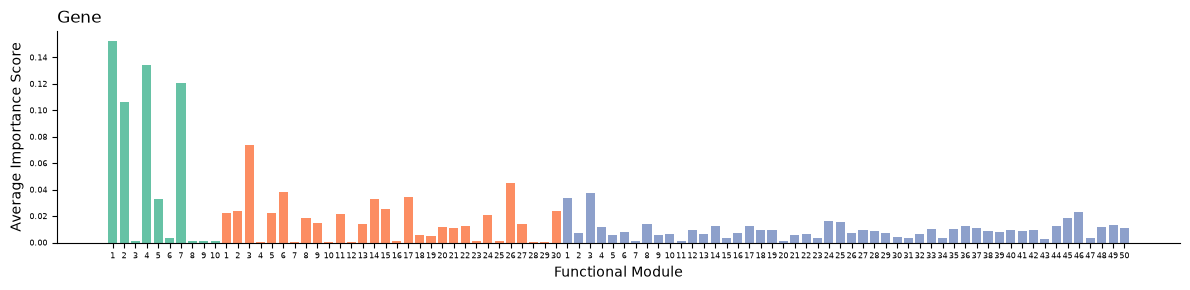

In [14]:
# Example plot of importance score to gene
gene_score = np.mean(importance_score[:,:input_size['G']],axis=1)
np.argsort(gene_score)[::-1]

modules = [f"{i+1}" for i in range(len(gene_score))]
modules_x = [i for m in encoded_modalities for i in range(1, latent_dim[m] + 1)]

# Color each modality's modules; dimensions also work with tuned settings.
colors = [sns.color_palette("Set2")[i]
          for i, m in enumerate(encoded_modalities) for _ in range(latent_dim[m])]

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, gene_score, color=colors)

ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Gene", fontsize=12, loc='left', pad=6)
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

Average metabolite importance for each functional module:

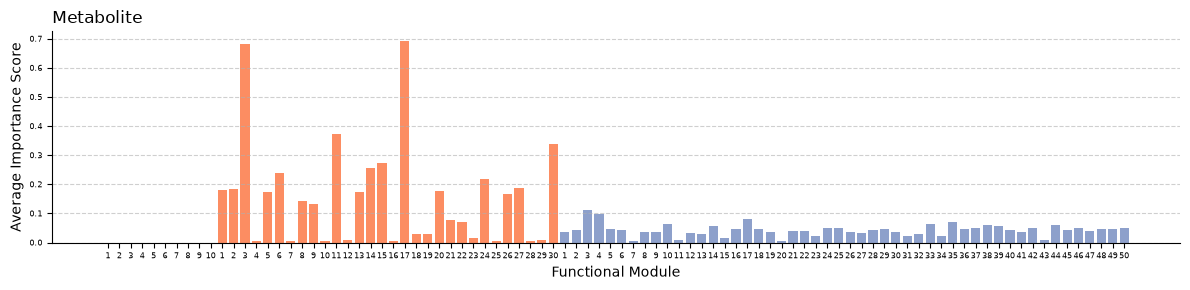

In [15]:
# importance score to metabolite
meta_score = np.mean(importance_score[:,(input_size['G']):(input_size['G']+input_size['M'])],axis=1)
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, meta_score, color=colors)

# Labels and style
ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Metabolite", fontsize=12, loc='left', pad=6)
ax.grid(True, linestyle='--', alpha=0.6, axis='y')
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

Average protein importance for each functional module:

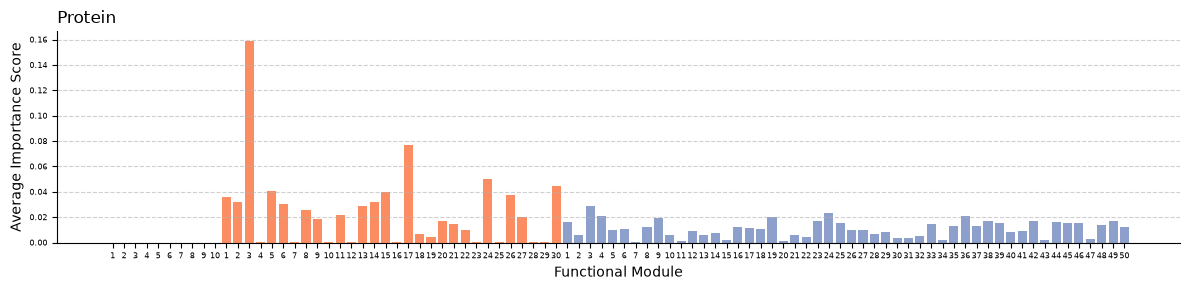

In [16]:
# importance score to protein
protein_score = np.mean(importance_score[:, input_size['G']+input_size['M']:],axis=1)
np.argsort(protein_score)[::-1]

modules = [f"{i+1}" for i in range(len(protein_score))]

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, protein_score, color=colors)

# Labels and style
ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Protein", fontsize=12, loc='left', pad=6)
ax.grid(True, linestyle='--', alpha=0.6, axis='y')
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

# Construct trajectory tree.

`construct_principal_tree` takes:

| Input | Meaning |
|---|---|
| `latent_embedding` | `(cells × time_points, latent_features)`, in cell/time order. |
| `time_length` | Observations per cell; equal lengths are required. |
| `cell_num` | Number of cells. |

Defaults initialize 15 intermediate and 6 endpoint clusters, automatically trim lineages to select the optimal tree (the final number of leaves may not be 6).

In [17]:
cell_num = len(dataset.samples)  # 50 cells in the bundled dataset
cell_lengths = [sample[0].shape[0] for sample in dataset.samples]
if len(set(cell_lengths)) != 1:
    raise ValueError("Tree construction requires equal-length cell trajectories.")
time_length = cell_lengths[0]  # 106 time points in the bundled dataset

cell_embeddings = latent_embedding.reshape(cell_num, time_length, latent_embedding.shape[1])

In [18]:
# Use the current constructor defaults, including automatic lineage trimming.
(trajectory_tree, growth_stage_matrix, bifurcation_point,
 sepration_time, projection_distances) = construct_principal_tree(
    latent_embedding, time_length, cell_num,
)


overK  trim trajectory (n:dist)             recK
────────────────────────────────────────────────────────────
    8  8:3.544 7:3.565 6:3.597 5:3.635 4:3.807 3:3.988 2:4.286 1:5.396      2



→ Selected n_before=15, K_actual=2.(recon dist = 4.3485)



fixed epsilon = 0.024395


   alpha   Val Entropy
───────────────────────


    0.00        0.6704


    0.03        0.6742


    0.05        0.6767


    0.08        0.6782


    0.10        0.6793

→ Selected alpha=0.00  (val entropy = 0.6704)



→ Construction error (all-cell reconstruction) = 5.265752  (K=2, epsilon=0.024395)



In [19]:
# Project cells to the tree. Retain the monotonic growth_stage_matrix from construction.
projected_growth_stage_matrix, projection_distances, segment__d, total_d = project_embeddings_to_tree(latent_embedding,
                                                                                    trajectory_tree,
                                                                                    time_length, stretch=0)
# Clustering
clustering_label = lineage_clustering(projection_distances, time_length, trajectory_tree)
clustering_label_all = np.array([item for item in clustering_label for _ in range(time_length)])

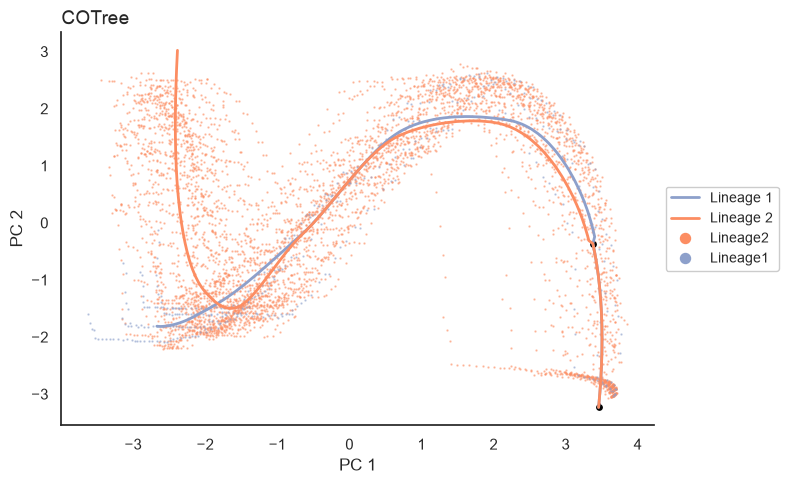

In [20]:
# Visualize the tree
vis_tree(latent_embedding, trajectory_tree, clustering_label_all, bifurcation_point, type="", save_path=None)

In [21]:
latent_embedding_G, latent_embedding_M, latent_embedding_P, _ = seperate_output(latent_embedding, latent_dim)
bifurcation_point_G, bifurcation_point_M, bifurcation_point_P, _ = seperate_output(bifurcation_point, latent_dim)
trajectory_tree_M = {}
trajectory_tree_P = {}
for leaf, lineage in trajectory_tree.items():
    _,trajectory_tree_M[leaf],trajectory_tree_P[leaf],_ = seperate_output(trajectory_tree[leaf], latent_dim)

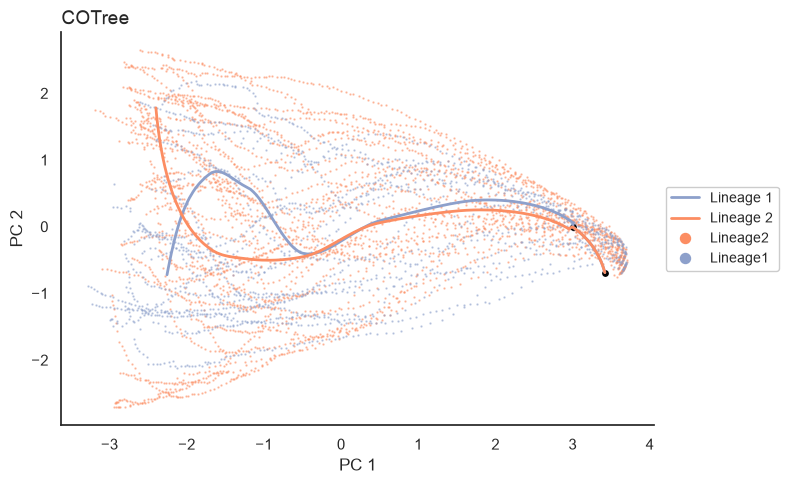

In [22]:
# Metabolite tree
growth_stage_matrix_M, projection_d_M, segment__d_M, total_d_M = project_embeddings_to_tree(latent_embedding_M,
                                                                                    trajectory_tree_M,
                                                                                    time_length, stretch=0)
clustering_label_M = lineage_clustering(projection_d_M, time_length, trajectory_tree_M)
clustering_label_M_all = np.array([item for item in clustering_label_M for _ in range(time_length)])
vis_tree(latent_embedding_M, trajectory_tree_M, clustering_label_M_all, bifurcation_point_M, type="", save_path=None)

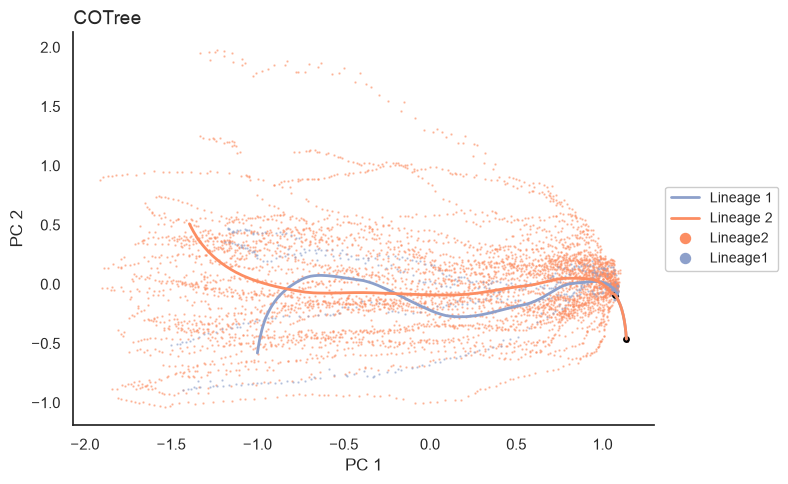

In [23]:
# Protein tree
growth_stage_matrix_P, projection_d_P, segment__d_P, total_d_P = project_embeddings_to_tree(latent_embedding_P,
                                                                                    trajectory_tree_P,
                                                                                    time_length, stretch=0)
clustering_label_P = lineage_clustering(projection_d_P, time_length, trajectory_tree_P)
clustering_label_P_all = np.array([item for item in clustering_label_P for _ in range(time_length)])
vis_tree(latent_embedding_P, trajectory_tree_P, clustering_label_P_all, bifurcation_point_P, type="", save_path=None)

# Predictive time and retrospective time

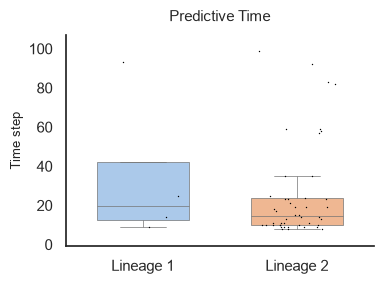

In [24]:
predictive_time_all = vis_predictive_time(trajectory_tree, projection_distances, bifurcation_point, clustering_label, time_length)

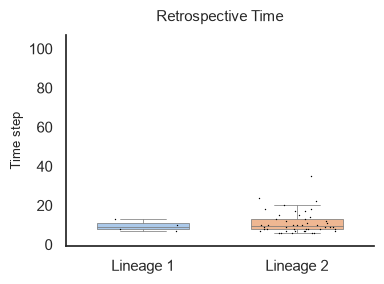

In [25]:
retrospective_time = vis_retrospective_time(trajectory_tree, growth_stage_matrix, sepration_time, clustering_label, time_length)

# Driver species detection

The `sepration_time` dictionary contains separation pseudotimes for the lineages:

In [26]:
sepration_time

{'Lineage1': np.float64(2.6198597988905887),
 'Lineage2': np.float64(2.6198597988905887)}

`extract_trajectory` combines the tree, lineage labels, and `sepration_time` with these aligned arrays:

| Input | Shape |
|---|---|
| `cell_growth_stage_matrix` | `(cells, time_points, lineages)` |
| `cell_data_raw` | `(cells, time_points, G+M+P features)`; these values are already processed. |
| `cell_embeddings` | `(cells, time_points, latent_features)` |

`list_truncation=80` excludes frame indices 80 onward. `inter=10` keep one observation every 10 time points to get robust change directions.

In [27]:
cell_growth_stage_matrix = growth_stage_matrix.reshape(cell_num,time_length,-1)
cell_data_raw = data_raw.reshape(cell_num, time_length, -1)

In [28]:
raw_data, encoded_data, weight, real_time, lineage_map = extract_trajectory(trajectory_tree,
                                                                cell_growth_stage_matrix,
                                                                cell_data_raw,
                                                                cell_embeddings,
                                                                clustering_label,
                                                                sepration_time,
                                                                list_truncation=80,
                                                                inter = 10)

Node 0: direction 1 = Lineage1, direction 2 = Lineage2


`driver_species_detection` uses the same model and the extracted dictionaries. `node_ind=0` selects the first comparison, identified by `lineage_map[0]`. Single-lineage results are skipped.

| Input | Meaning |
|---|---|
| `input_size`, `device` | Processed dimensions and computation device. |
| `sparse_penalty` | Sparsity regularization strength. |
| `epoches`, `learning_rate` | Maximum epochs and step size. |

In [29]:
diff_score_node1, diff_species1 = None, None
if 0 in lineage_map:
    diff_score_node1, diff_species1 = driver_species_detection(RL_model,
                                      0, 
                                      raw_data, 
                                      encoded_data, 
                                      weight, 
                                      input_size,
                                      device,
                                      lineage_map = lineage_map,
                                      sparse_penalty = 0.01, 
                                      epoches = 300, 
                                      learning_rate = 0.001)
else:
    print("No bifurcation was selected; there are no driver groups to compare.")

Epoch 10/300, Loss: -0.960573, Cosine (direction 1): 0.635632, Cosine (direction 2): 0.637309, regularization: 0.308469
Epoch 20/300, Loss: -1.060276, Cosine (direction 1): 0.665787, Cosine (direction 2): 0.674403, regularization: 0.277136
Epoch 30/300, Loss: -1.132402, Cosine (direction 1): 0.684386, Cosine (direction 2): 0.702275, regularization: 0.252237
Epoch 40/300, Loss: -1.264582, Cosine (direction 1): 0.716017, Cosine (direction 2): 0.785220, regularization: 0.235115
Epoch 50/300, Loss: -1.407337, Cosine (direction 1): 0.776396, Cosine (direction 2): 0.853520, regularization: 0.221087


Epoch 60/300, Loss: -1.504345, Cosine (direction 1): 0.827493, Cosine (direction 2): 0.884620, regularization: 0.206335
Epoch 70/300, Loss: -1.567590, Cosine (direction 1): 0.861483, Cosine (direction 2): 0.898832, regularization: 0.191270


Epoch 80/300, Loss: -1.616196, Cosine (direction 1): 0.883276, Cosine (direction 2): 0.911287, regularization: 0.176973
Epoch 90/300, Loss: -1.651822, Cosine (direction 1): 0.900502, Cosine (direction 2): 0.915774, regularization: 0.163084
Epoch 100/300, Loss: -1.679234, Cosine (direction 1): 0.912223, Cosine (direction 2): 0.918483, regularization: 0.150277
Epoch 110/300, Loss: -1.700622, Cosine (direction 1): 0.920463, Cosine (direction 2): 0.920532, regularization: 0.139270
Epoch 120/300, Loss: -1.719109, Cosine (direction 1): 0.926748, Cosine (direction 2): 0.922041, regularization: 0.128632


Epoch 130/300, Loss: -1.735245, Cosine (direction 1): 0.931694, Cosine (direction 2): 0.923719, regularization: 0.119362
Epoch 140/300, Loss: -1.749008, Cosine (direction 1): 0.935794, Cosine (direction 2): 0.925312, regularization: 0.111277


Epoch 150/300, Loss: -1.761861, Cosine (direction 1): 0.939200, Cosine (direction 2): 0.926878, regularization: 0.103432
Epoch 160/300, Loss: -1.773517, Cosine (direction 1): 0.941948, Cosine (direction 2): 0.928462, regularization: 0.096115
Epoch 170/300, Loss: -1.784181, Cosine (direction 1): 0.944300, Cosine (direction 2): 0.929840, regularization: 0.089230
Epoch 180/300, Loss: -1.794277, Cosine (direction 1): 0.946380, Cosine (direction 2): 0.931005, regularization: 0.082438
Epoch 190/300, Loss: -1.802915, Cosine (direction 1): 0.948281, Cosine (direction 2): 0.932122, regularization: 0.076957


Epoch 200/300, Loss: -1.811005, Cosine (direction 1): 0.949940, Cosine (direction 2): 0.933046, regularization: 0.071515
Epoch 210/300, Loss: -1.817968, Cosine (direction 1): 0.951442, Cosine (direction 2): 0.933802, regularization: 0.066804


Epoch 220/300, Loss: -1.825253, Cosine (direction 1): 0.953308, Cosine (direction 2): 0.934505, regularization: 0.062164
Epoch 230/300, Loss: -1.831792, Cosine (direction 1): 0.955044, Cosine (direction 2): 0.935057, regularization: 0.057860
Epoch 240/300, Loss: -1.837357, Cosine (direction 1): 0.956276, Cosine (direction 2): 0.935642, regularization: 0.054157
Epoch 250/300, Loss: -1.842506, Cosine (direction 1): 0.957235, Cosine (direction 2): 0.936140, regularization: 0.050530
Epoch 260/300, Loss: -1.847102, Cosine (direction 1): 0.958046, Cosine (direction 2): 0.936498, regularization: 0.047122


Epoch 270/300, Loss: -1.851243, Cosine (direction 1): 0.958703, Cosine (direction 2): 0.936795, regularization: 0.043980
Epoch 280/300, Loss: -1.855198, Cosine (direction 1): 0.959243, Cosine (direction 2): 0.936995, regularization: 0.040703


Epoch 290/300, Loss: -1.858668, Cosine (direction 1): 0.959684, Cosine (direction 2): 0.937160, regularization: 0.037964
Epoch 300/300, Loss: -1.861653, Cosine (direction 1): 0.960028, Cosine (direction 2): 0.937326, regularization: 0.035490


threshold selection: knee_k=96, floor_k=2, target_k=24, selected_k=24 of 1132 species; tau=0.01566

Node 0 — detected driver species (by direction):
  Species index 16: faster increase in direction 2 (Lineage2)
  Species index 84: faster increase in direction 1 (Lineage1)
  Species index 85: faster increase in direction 1 (Lineage1)
  Species index 94: faster increase in direction 2 (Lineage2)
  Species index 95: faster increase in direction 2 (Lineage2)
  Species index 153: faster increase in direction 1 (Lineage1)
  Species index 154: faster increase in direction 1 (Lineage1)
  Species index 179: faster increase in direction 2 (Lineage2)
  Species index 180: faster increase in direction 2 (Lineage2)
  Species index 181: faster increase in direction 2 (Lineage2)
  Species index 182: faster increase in direction 2 (Lineage2)
  Species index 415: faster increase in direction 1 (Lineage1)
  Species index 416: faster increase in direction 1 (Lineage1)
  Species index 417: faster increase 

`plot_species_scores` takes the coefficient vector, aligned species names, `lineage_map`, the node index, and selected species indices. `ax` selects the plotting axes. By default, it shows up to 20 selected species; signs indicate the two comparison directions.

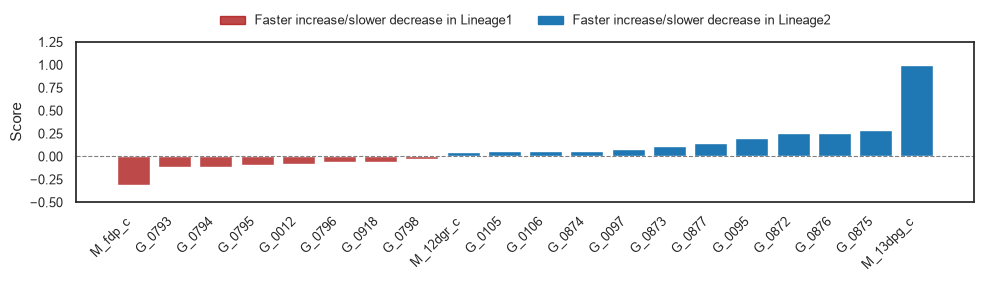

In [30]:
if diff_score_node1 is not None:
    fig, ax = plt.subplots(figsize=(10, 3))
    plot_species_scores(diff_score_node1, species, lineage_map, 0, diff_species1, ax=ax)
    # Place the legend above the plot, leaving room for species labels.
    ax.legend(handles=ax.get_legend().legend_handles, loc="lower center",
              bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=9, frameon=False)
    plt.tight_layout()
    plt.show()
